# MRMS reflectivity and objects tutorial

Walks through `py_obj_plotting`'s standalone spatial-map capabilities against a single, real, objectively-chosen MRMS case: **2023-05-13 00:00:15 UTC**.

This time was picked by evidence, not guessed: a scan of every May 2023 23Z file and every May/June 2023 00Z file in a local `test_mrms/` archive for fraction-of-pixels >=35/40 dBZ (excluding MRMS's `-999` no-coverage sentinel, with `-99` clipped to 0 first) found this time has the highest storm coverage of all 92 scanned times (0.97% of valid pixels >=35 dBZ). Its real object file also has all 3 storm modes present (55 cellular / 4 mixed / 2 linear of 61 objects) -- the same-day 23Z file has zero linear objects, confirming 00Z is the better choice on both criteria independently.

Three panels, each a real `py_obj_plotting` spatial-map capability:

1. **Native resolution** -- the raw MRMS GRIB2 observation, no regridding.
2. **Interpolated to a model grid** -- the same observation, interpolated onto a real MPAS full-CONUS grid and restricted to the eastern 2/3 of CONUS.
3. **Objects colored by storm mode** -- identified MRMS storm objects for this time, shaded by `is_linear` category (cellular/mixed/linear).

All data is bundled in `sample_data/mrms_case/` (see `sample_data/build_mrms_case.py` for the exact, kept regeneration script) -- no external dataset needed.


In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from IPython.display import Image, display

from py_obj_plotting.drivers.plot_reflectivity_maps import run_one_case as run_reflectivity_case
from py_obj_plotting.plots.mrms_object_map import grid_extent, plot_mrms_object_map
from python_obj.obj_core import read_object_file


## Step 1 -- Native-resolution reflectivity

`configs/config_sample_mrms_reflectivity_native.yaml` (`source: mrms_native`) reads the raw compressed GRIB2 file directly -- no interpolation, no target grid, just the native MRMS product at its own resolution.


Reflectivity map: source='mrms_native', input_dir=/Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/sample_data/mrms_case/mrms_native/20230513, times.mode='full'
  discovered 1 file(s), 1 selected


  wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_mrms_reflectivity_native/refl_mrms_native_20230513_000015.png
Wrote 1 image(s)


/opt/anaconda3/envs/pysteps_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/pysteps_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


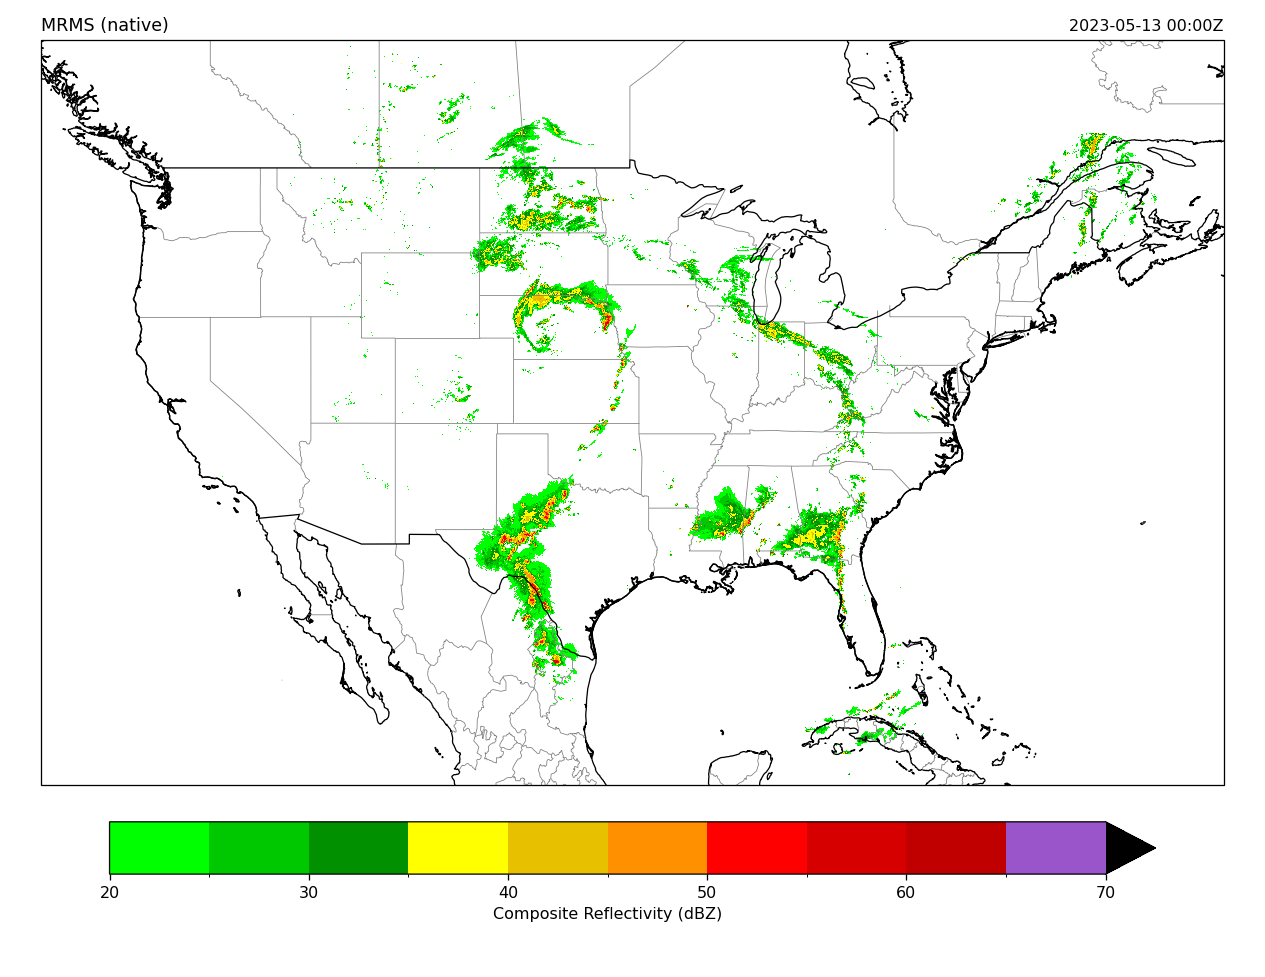

In [2]:
native_paths = run_reflectivity_case("../configs/config_sample_mrms_reflectivity_native.yaml")
print(f"Wrote {len(native_paths)} image(s)")
display(Image(filename=native_paths[0]))


## Step 2 -- Interpolated to a model grid (eastern 2/3 CONUS)

`configs/config_sample_mrms_reflectivity_interp.yaml` (`source: mrms_interp`) reads the same observation already interpolated onto a real MPAS full-CONUS target grid and cropped to the eastern-2/3-CONUS region (`python_obj.obj_core.conus_mask_east`'s own kept-region bounding box) -- the interpolation itself was performed once by `sample_data/build_mrms_case.py`, reusing `python_obj`'s existing conservative-regridding pipeline; `py_obj_plotting` itself never regrids, only plots.


Reflectivity map: source='mrms_interp', input_dir=/Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/sample_data/mrms_case/mrms_interp, times.mode='full'
  discovered 1 file(s), 1 selected


/opt/anaconda3/envs/pysteps_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


  wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_mrms_reflectivity_interp/refl_mrms_interp_20230513_000015.png
Wrote 1 image(s)


/opt/anaconda3/envs/pysteps_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


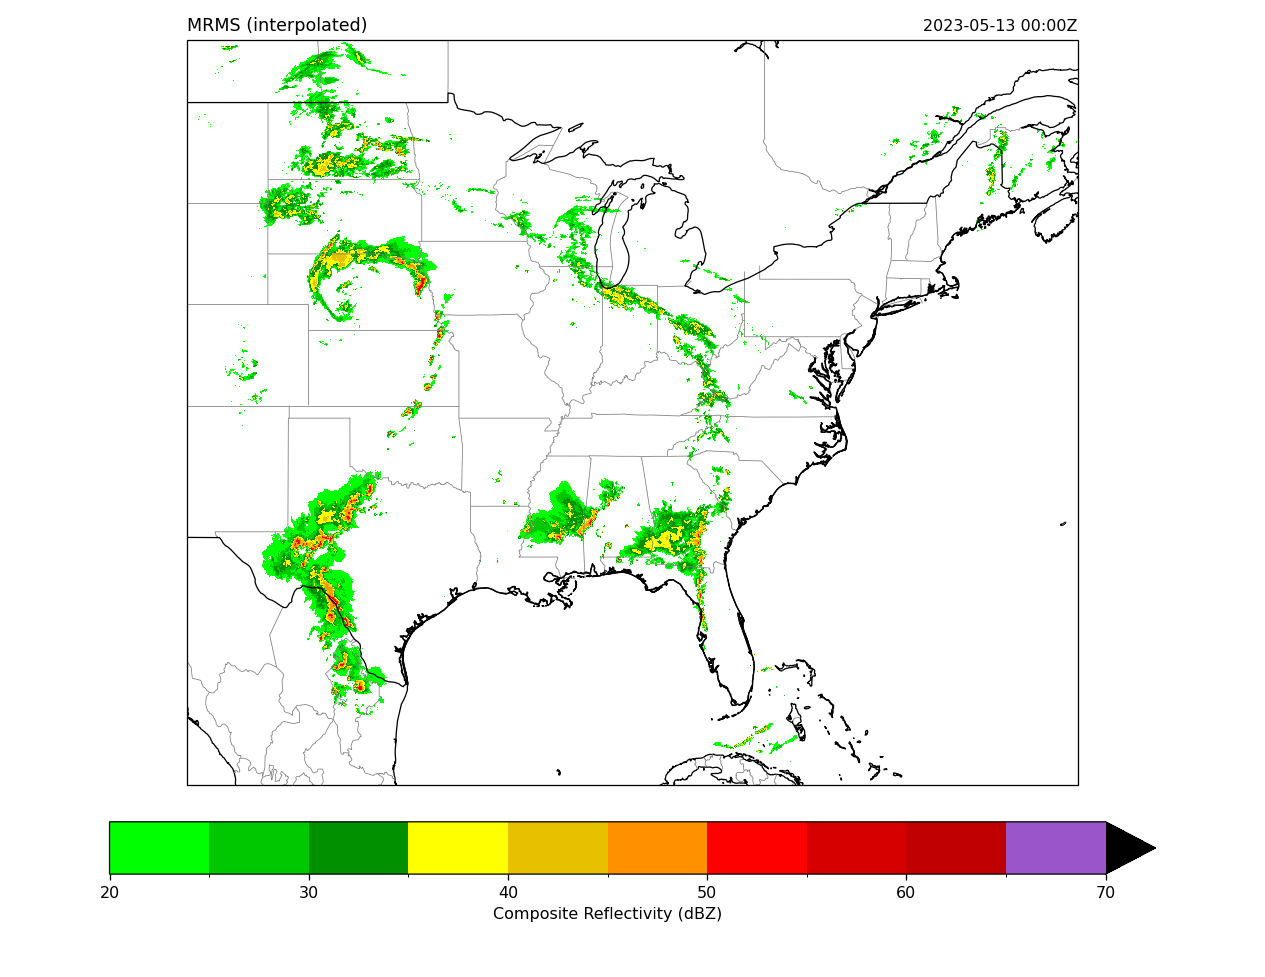

In [3]:
interp_paths = run_reflectivity_case("../configs/config_sample_mrms_reflectivity_interp.yaml")
print(f"Wrote {len(interp_paths)} image(s)")
display(Image(filename=interp_paths[0]))


## Step 3 -- MRMS objects colored by storm mode

`plots.mrms_object_map.plot_mrms_object_map` reads `python_obj`'s own object-file schema directly and shades every identified storm object by its `is_linear` category (0=cellular=orange, 1=possibly linear=purple, 2=linear=blue), with a small centroid marker per object. This uses the real, already-identified MRMS object file for this exact time (`sample_data/mrms_case/mrms_objects/obj_obs_20230513_000015.nc`), cropped to the same eastern-2/3-CONUS region as Step 2 for a directly comparable domain.


61 objects: 55 cellular, 4 mixed, 2 linear


/opt/anaconda3/envs/pysteps_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/pysteps_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


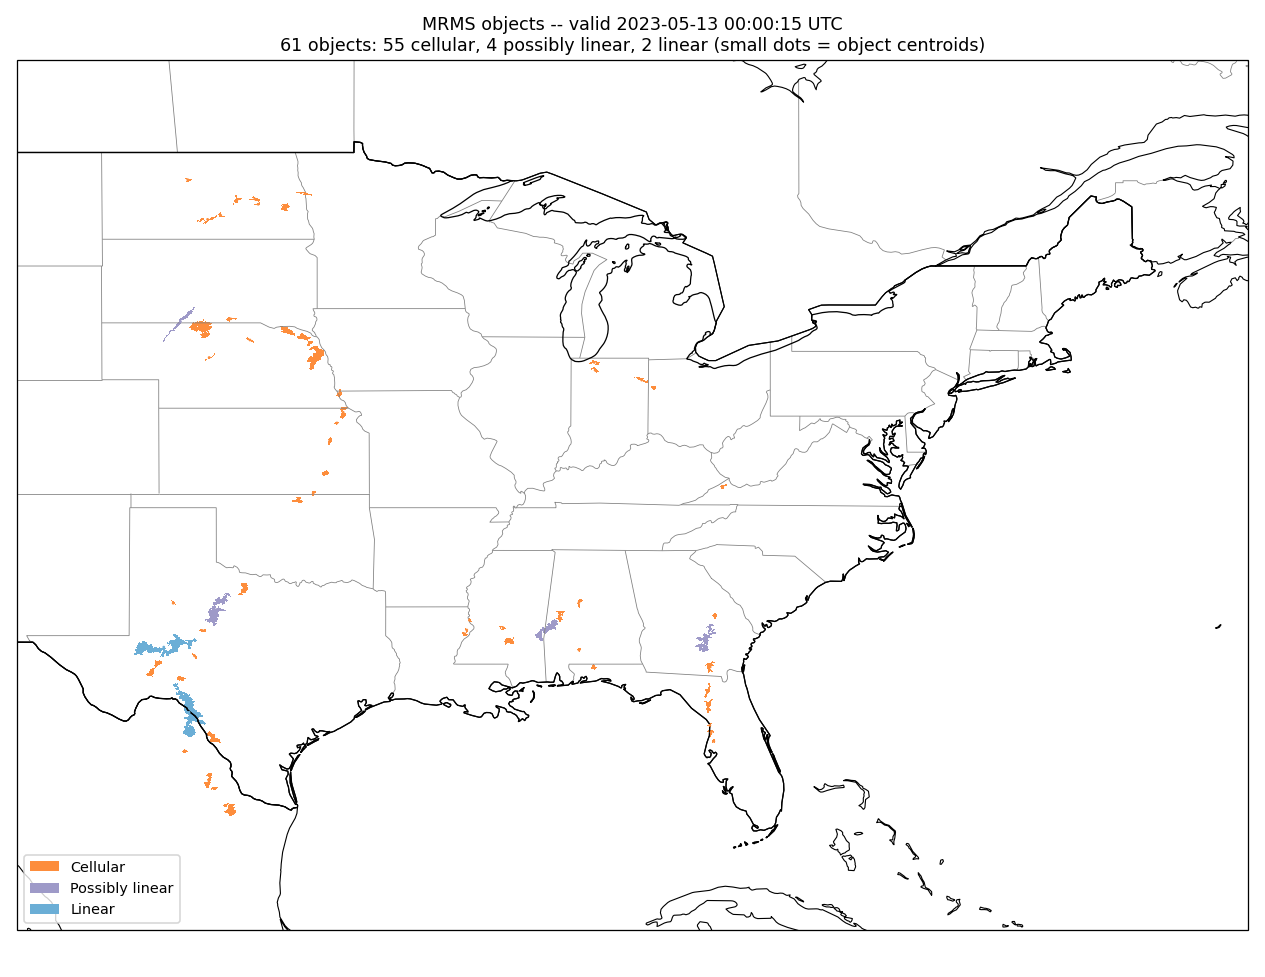

In [4]:
contents = read_object_file("../sample_data/mrms_case/mrms_objects/obj_obs_20230513_000015.nc")
extent = grid_extent(contents.lat2d, contents.lon2d)

n_by_type = {0: 0, 1: 0, 2: 0}
for obj in contents.objects:
    n_by_type[obj.is_linear] += 1
print(f"{len(contents.objects)} objects: {n_by_type[0]} cellular, {n_by_type[1]} mixed, {n_by_type[2]} linear")

out_dir = "output/sample_mrms_objects"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "mrms_objects_storm_mode_20230513_000015.png")
plot_mrms_object_map(contents, out_path, extent)
display(Image(filename=out_path))


## Closing

All three panels share a consistent domain (the eastern 2/3 of CONUS, per `conus_mask_east`) and the same real, objectively-chosen valid time -- Step 1 shows the raw observation at its native resolution, Step 2 shows the same field ready for direct comparison against a model forecast on that model's own grid, and Step 3 shows what `python_obj`'s object-identification pipeline extracted from it, classified by storm mode.

See `CONFIG_REFERENCE.md` for every field of `ReflectivityMapConfig`, and `README.md` for the full capability list (object spatial maps, paintball plots, matching-timeseries verification suite) this package provides beyond what's shown here.
